## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Arya Kumar

**Date:** 10/15

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [1]:
#Question 1.1 - running the data set

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

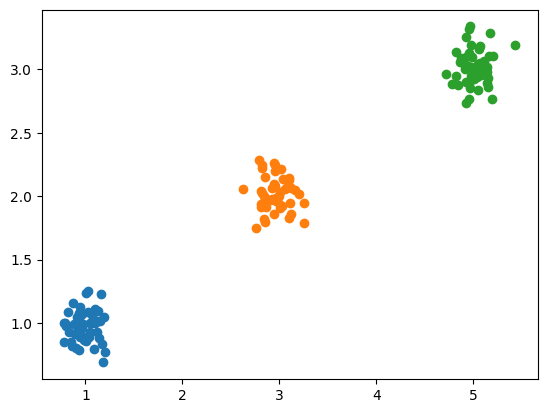

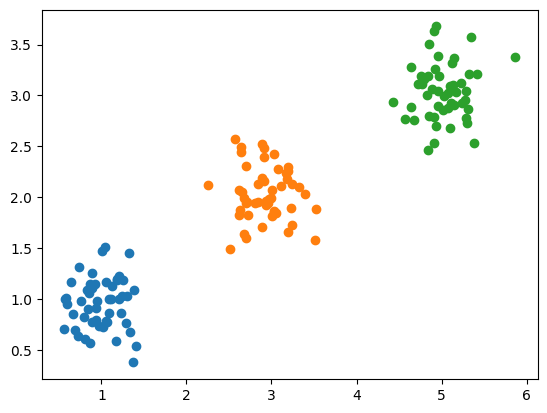

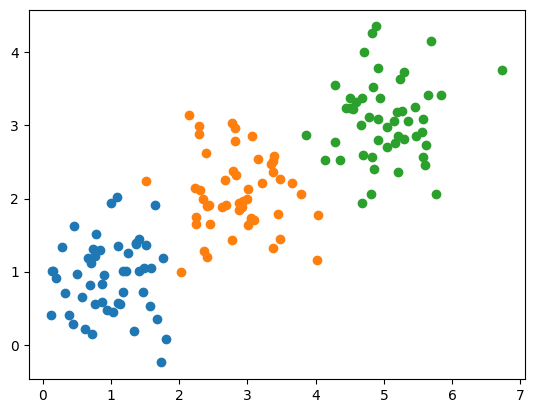

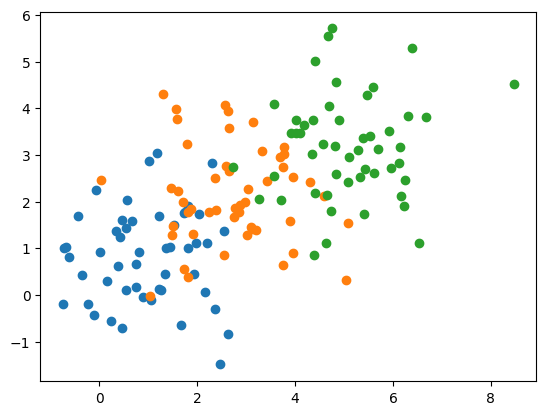

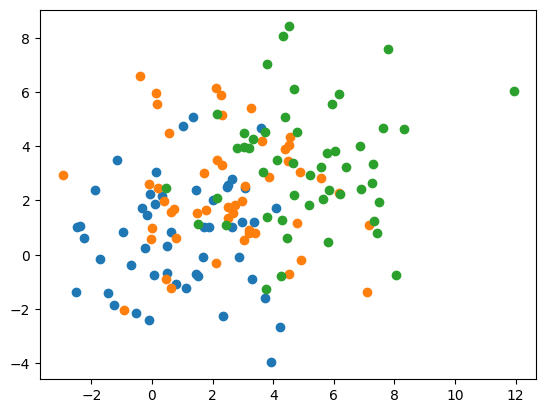

In [4]:
#Question 1.2 - making scatterplots - designating the five datasets from above and the different noise levels and running a for loop to go through each of the five datasets and separating each of the five by group and making a scatter plot for each one with different colors to differentiate
#As the noise increases from 0.125 to 2.0, the clusters become less visually distinct. At lower noise levels, the three groups are concentrated around their specific center and they are easy to distinguish. However, as noise increases, the points become more spread out and begin to overlap with other groups and it's difficult to tell them apart without color coding.

import matplotlib.pyplot as plt

sets = [df0_125, df0_25, df0_5, df1_0, df2_0]
different_noise = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(sets, different_noise):
    for group in ['a','b','c']:
        subset = df[df['group'] == group]
        plt.scatter(subset['x1'], subset['x2'], label=group)
    plt.show()


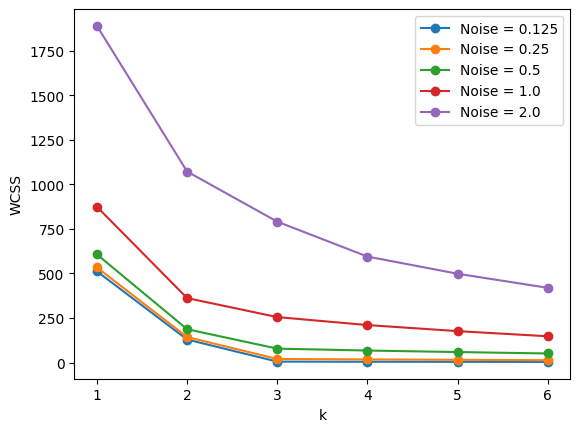

In [9]:
#Question 1.3 - importing the relevant datasets and looping through each set and run KMeans for k values from 1 to 6. Then, plotting these values on the same graph to compare how different levels of noise affects the scree curves.
#As the noise increases, the WCSS values increase across all values of k. At lower noise levels of 0.125 and 0.5, there is a relatively clear elbow at k = 3, but at noise levels of 1.0 and 2.0, the curves decrease more gradually and the elbow is not clear anymore, which makes it much harder to determine the optimal k.
from sklearn.cluster import KMeans


for df, noise in zip(sets, different_noise):
    X = df[['x1', 'x2']]
    wcss = []

    for k in range(1, 7):
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
        kmeans.fit(X)
        wcss.append(kmeans.inertia_)

    plt.plot(k_values, wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('k')
plt.ylabel('WCSS')
plt.legend()
plt.show()

In [13]:
#Question 2.1 - loading dataset
from google.colab import files
uploaded = files.upload()


Saving SIPRI Military Expenditure Database.csv to SIPRI Military Expenditure Database (2).csv


In [17]:
df = pd.read_csv("SIPRI Military Expenditure Database (2).csv")
df.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [19]:
#dropping nan and filtering to only 2020
df = df[df['Year'] == 2020]
df = df.dropna()
df.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [20]:
#checking there are 148
df["Country"].nunique()

148

In [21]:
#checking for duplicate countries
df['Country'].duplicated().sum()

np.int64(0)

In [22]:
#checking data types to make sure everything is in a good format
df.dtypes

,0
index,int64
Year,int64
Country,object
Spending (2020 USD),float64
Percent of GDP,float64
Percent of Government Spending,float64
Spending per Capita,float64


In [23]:
#checking there is no more nans
df.isna().sum()

,0
index,0
Year,0
Country,0
Spending (2020 USD),0
Percent of GDP,0
Percent of Government Spending,0
Spending per Capita,0


No more cleaning is necessary.

---



In [24]:
#2.2 - importing
from sklearn.preprocessing import MinMaxScaler

In [26]:
# Normalizing both variables to a range of 0 to 1 to account for large dfferences between the numbers
X = df[['Spending (2020 USD)', 'Spending per Capita']]
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

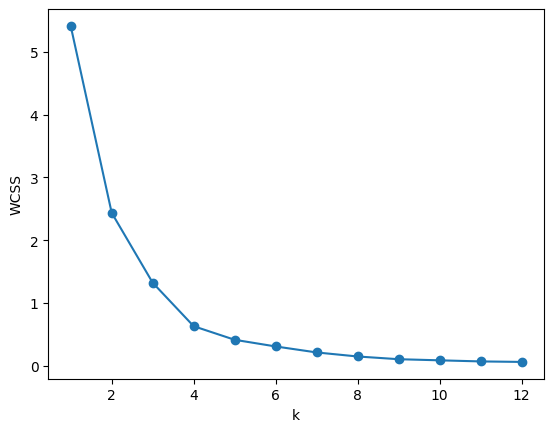

In [32]:
#creating the scree plot - it looks like k=4 is the optimal choice as it seems like it's where the elbow is.

wcss = []
for k in range(1, 13):
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 13), wcss, marker='o')
plt.xlabel('k')
plt.ylabel('WCSS')
plt.show()

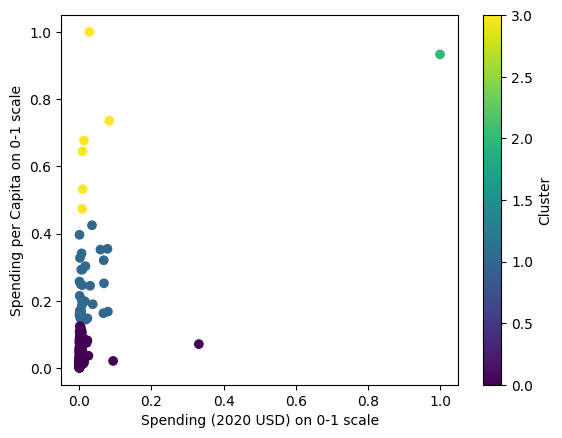

In [33]:
#with the chosen K, Run KMeans with 4 clusters based on the scree plot, assign each country to a cluster, and create a scatterplot of the normalized spending variables colored by cluster membership.
kmeans = KMeans(n_clusters=4, random_state=100, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=df['cluster'], cmap='viridis')

plt.xlabel('Spending (2020 USD) on 0-1 scale')
plt.ylabel('Spending per Capita on 0-1 scale')
plt.colorbar(label='Cluster')
plt.show()

In [34]:
#making the describe table with the suggested function
df.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita']].describe()

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                      30.0   17077.591354  20583.053357     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   
3                       6.0   19443.362047  22861.507114    6095.708713   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          2294.039665    5857.060906   26296.001003   61712.537169   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          7023.251766    8624.225729   18857.070183   64558.400000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0    80.061470   83.501824     0.580129   
1                      30.0   607.478618  206.928757   362.467076   
2                       1.0  2351.631858         NaN  2351.631858   
3                       6.0  1706.721916  466.375705  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    47.056944   125.387558   314.201312  
1         422.208252   579.004604   757.328513  1070.623322  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3        1412.083201  1665.447478  1817.219993  2520.398541

In [36]:
df[df['Country'] == 'United States of America'] #the united states is in cluster 2

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,2


In [37]:
df[['Country', 'cluster']].sort_values('cluster')

#The US is interestingly in its own cluster 2. Cluster 0 contains the majority of countries, including China and India, which have relatively low spending per capita despite having some of the largest total military expenditures. Cluster 1 consists largely of developed economies, particularly European countries, with moderate to high military spending per capita. Cluster 2 contains only the United States, suggesting that its exceptionally high total military spending makes it an outlier compared to other countries. Finally, Cluster 3 contains countries such as Saudi Arabia, Israel, Kuwait, Singapore, Oman, and Norway, which have particularly high military spending per capita despite having much smaller total military expenditures than the United States.

,Country,cluster
32,Afghanistan,0
66,Albania,0
100,Algeria,0
134,Angola,0
168,Argentina,0
...,...,...
2582,Israel,3
4656,Singapore,3
4486,Saudi Arabia,3
4044,Oman,3


In [38]:
#2.3 - repeating same steps as before
X2 = df[['Percent of Government Spending', 'Percent of GDP']]

scaler = MinMaxScaler()
X2_scaled = scaler.fit_transform(X2)

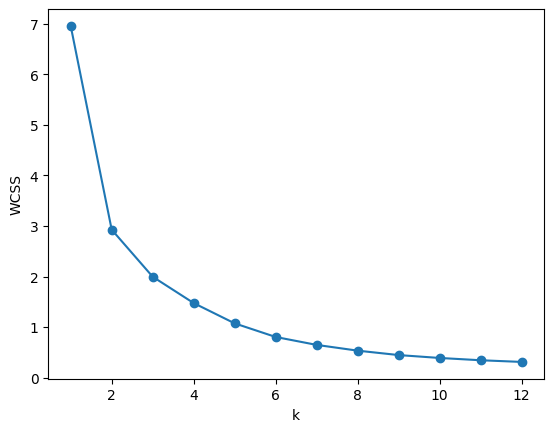

In [45]:
#optimal is a little less clear, but I would say maybe 5.
wcss2 = []

for k in range(1, 13):
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(X2_scaled)
    wcss2.append(kmeans.inertia_)

plt.plot(range(1, 13), wcss2, marker='o')
plt.xlabel('k')
plt.ylabel('WCSS')
plt.show()

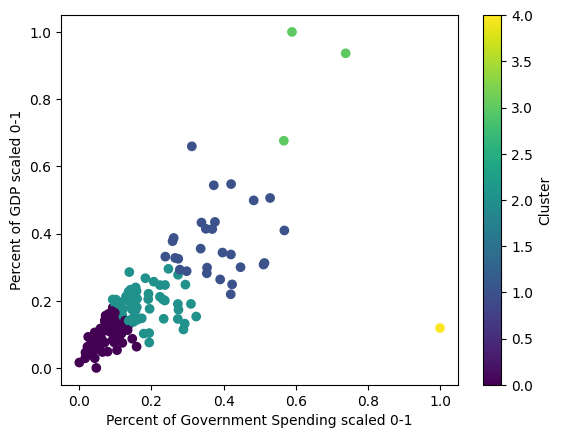

In [41]:
kmeans2 = KMeans(n_clusters=5, random_state=100, n_init=10)
df['cluster2'] = kmeans2.fit_predict(X2_scaled)

plt.scatter(X2_scaled[:, 0], X2_scaled[:, 1],
            c=df['cluster2'], cmap='viridis')

plt.xlabel('Percent of Government Spending scaled 0-1')
plt.ylabel('Percent of GDP scaled 0-1')
plt.colorbar(label='Cluster')
plt.show()

In [42]:
df[['Country', 'cluster2']].sort_values('cluster2')

#the US is no longer in its own category and rather Belarus is in its own cluster at 4. This suggests that while the United States is exceptional in the total amount it spends, it is less exceptional when military spending is measured relative to the size of its economy and government budget. Saudi Arabia and Oman both remain in cluster three, suggesting that Saudi Arabia and Oman have both high military spending per capita and high military spending relative to their GDP and government budgets.Belarus is an interesting outlier because its military spending represents an exceptionally large share of government expenditure, but its share of GDP is not comparably extreme.

,Country,cluster2
66,Albania,0
168,Argentina,0
270,Austria,0
508,Benin,0
542,Bolivia,0
...,...,...
4894,Sri Lanka,2
100,Algeria,3
4486,Saudi Arabia,3
4044,Oman,3


In [43]:
#2.4 - repeat 2.2/2.3 but with four variables now, so no scatter plot

X3 = df[['Spending (2020 USD)', 'Spending per Capita',
         'Percent of Government Spending', 'Percent of GDP']]
scaler = MinMaxScaler()
X3_scaled = scaler.fit_transform(X3)

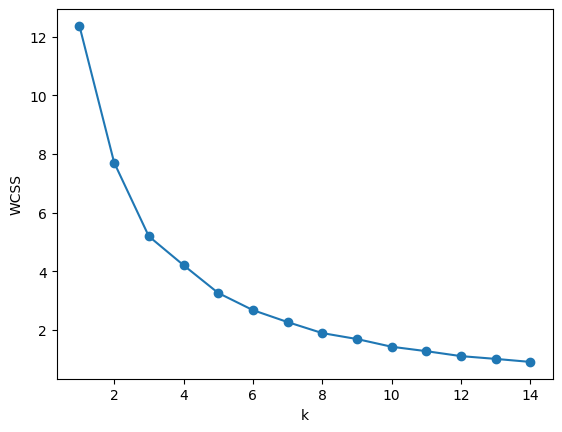

In [48]:
# I'd say optimal k = 5
wcss3 = []

for k in range(1, 15):
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(X3_scaled)
    wcss3.append(kmeans.inertia_)

plt.plot(range(1, 15), wcss3, marker='o')
plt.xlabel('k')
plt.ylabel('WCSS')
plt.show()

In [50]:
kmeans3 = KMeans(n_clusters=5, random_state=100, n_init=10)
df['cluster3'] = kmeans3.fit_predict(X3_scaled)
df.groupby('cluster3')[['Spending (2020 USD)', 'Spending per Capita',
                        'Percent of Government Spending', 'Percent of GDP']].describe()

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster3                                                                   
0                       86.0    4513.543790  27841.230783       8.622460   
1                       26.0   15330.618681  18923.469359     405.790494   
2                        5.0   21878.058451  24674.937388    6095.708713   
3                       30.0    9073.543709  18135.032885     163.926877   
4                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster3                                                               
0             81.022976     288.061512    1138.618231  257973.429834   
1           3176.345598    5857.060906   21818.934764   60675.039625   
2           6941.042345    9978.571429   21816.569767   64558.400000   
3            522.737081    1663.090134    8646.648849   72937.064048   
4         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                       86.0    70.290644  ...                       0.053006   
1                       26.0   612.677541  ...                       0.044645   
2                        5.0  1779.854530  ...                       0.180654   
3                       30.0   215.920971  ...                       0.136403   
4                        1.0  2351.631858  ...                       0.081976   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1         0.052209           26.0  0.016585  0.005525  0.006273  0.013689   
2         0.225050            5.0  0.067725  0.028372  0.029429  0.053553   
3         0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
4         0.081976            1.0  0.037179       NaN  0.037179  0.037179   

                                        
               50%       75%       max  
cluster3                                
0         0.012532  0.016783  0.026340  
1         0.015324  0.020431  0.028132  
2         0.064961  0.092211  0.098470  
3         0.032148  0.040637  0.066600  
4         0.037179  0.037179  0.037179  

[5 rows x 32 columns]

In [51]:
#The US returns to forming it's own category of cluster 4. In Question 2.2, the United States formed its own cluster because its total military spending was exceptionally high. In Question 2.3, it was grouped with countries like Russia, India, and Pakistan because military spending as a percentage of GDP and government expenditure was more comparable.
#Now, when combining all four variables, the United States again forms its own cluster. This suggests that its exceptionally high absolute military spending continues to distinguish the country. Cluster one is kind of ist own category with developed couuntries like Germany, France, the United Kingdom, Japan, Australia, and Canada. These countries have higher spending per capita than most countries but do not devote exceptionally large percentages of their GDP or government budgets to defense. In Question 2.3, Belarus formed its own cluster because of its exceptionally high percentage of government spending allocated to defense. In Question 2.4, it joins Cluster 3.
df[['Country', 'cluster3']].sort_values('cluster3')

,Country,cluster3
32,Afghanistan,0
66,Albania,0
134,Angola,0
168,Argentina,0
474,Belize,0
...,...,...
5064,Taiwan,3
5438,Ukraine,3
5404,Uganda,3
5234,Togo,3


2.5 - Yes, it was helpful in helping us discover patterns that would otherwise be hard to spot. It was interesting how cluster membership would shift depending on whether we measured in terms of absolute spending or spending relative to GDP and government expenditure. However, the results are certainly dependent on which variables are chosen, so it does take a few different tries with different variables to get a clearer picture. Relying on only one of 2.2/2.3/or2.4 to tell us something would be an incomplete picture of military spending.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 51422ec04e3a0e55ea71ff4cd12c456b7ebf32e7
- **AI tool and model used:** Chat GPT 6

### *Prompts used

1. I attached the downlaoded version of this notebook and asked it to look over my answer snad give feedback. I said "check the code and see what can be improved/made more efficient/clearer"

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. For question 1.3, k_values is undefined. (not sure what happened here - I definintely had working code before, maybe accidentally changed something after I ran it and didn't rerun it and realize I had made an error.
2. All of the scatterplots in 1.2 have no title or axis labels
3. suggested using this for uploading csv - from google.colab import files

uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])

4. also verify no further cleaning is needed with df.shape.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | Yes, this is fair. This was a minor mistake that I did not notice when I was rewriting a part to make it more consistent.
| 2 | **Accept** / modify / reject | This is also fair. I did not think it was important to have these since they were for my analysis, but it's fair to include them to make analysis and presentation easier. More so for the axis labels and not the title. I don't think the titles are necessary.
| 2 | Accept / modify / **reject** | I think is a very minor touchup that I do not quite understand, so I'd rather stick with what I know to do.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

#1.3

sets = [df0_125, df0_25, df0_5, df1_0, df2_0]
different_noise = [0.125, 0.25, 0.5, 1.0, 2.0]
k_values = range(1, 7)

for df, noise in zip(sets, different_noise):
    X = df[['x1', 'x2']]
    wcss = []

    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
        kmeans.fit(X)
        wcss.append(kmeans.inertia_)

    plt.plot(k_values, wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Scree Plot for Different Noise Levels')
plt.legend()
plt.show()

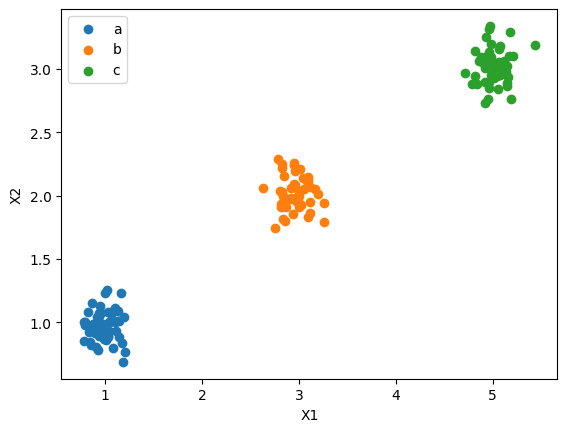

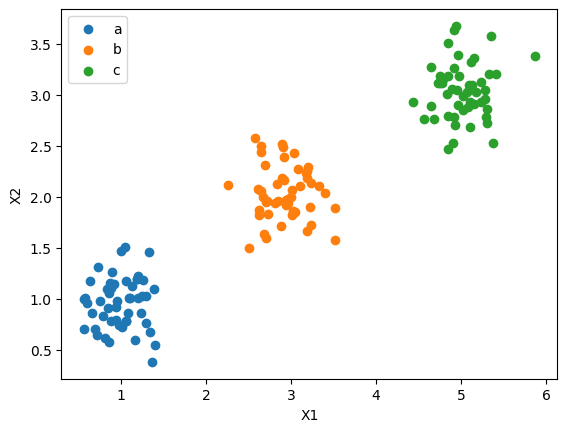

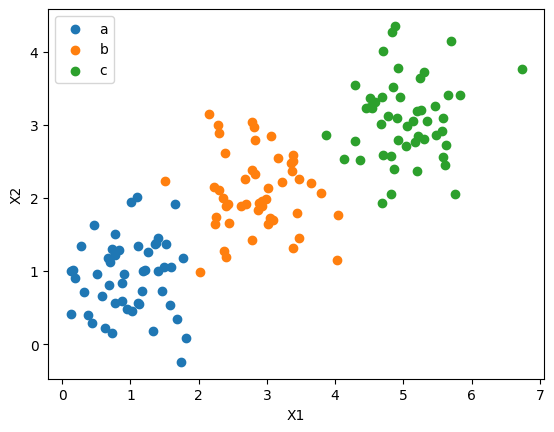

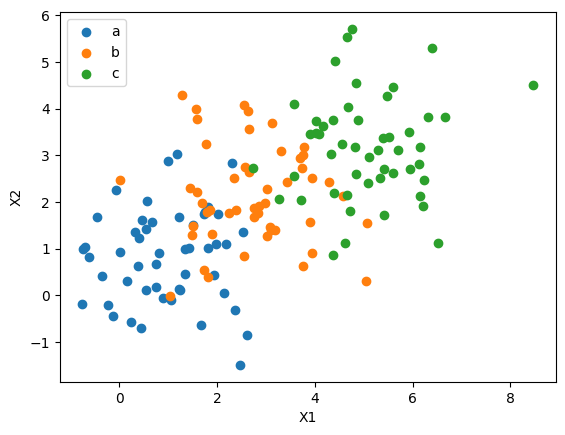

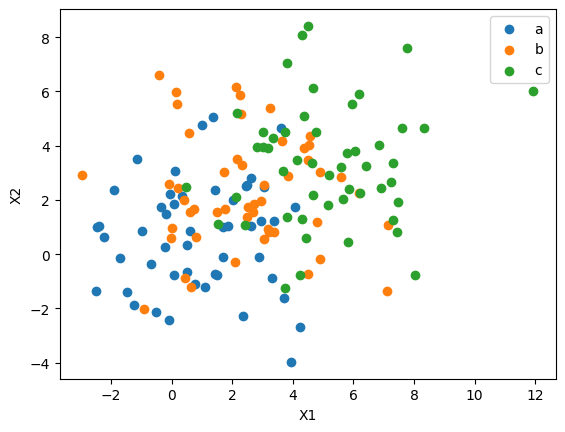

In [52]:
#1.2
sets = [df0_125, df0_25, df0_5, df1_0, df2_0]
different_noise = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(sets, different_noise):
    plt.figure()

    for group in ['a', 'b', 'c']:
        subset = df[df['group'] == group]
        plt.scatter(subset['x1'], subset['x2'], label=group)

    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    plt.show()

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The Chat gpt 6 model reviewed areas of my code that could have used improvements. I found some stuff minorly helpful and some stuff sort of unnesccesary. I.e one of the suggestions I did not even include because it was like a suggestion of how to improve uploading my notebook to chat for review. The suggestion for 1.3 was definitely a good catch because i would have lost points from a dumb oversight. I did not need to verify it besides just running it and making sure it worked as it was a minor fix. The suggestion for 1.2 was not a material change. The change was to add labels basically to improve clarity. It's a good suggestion, since plresentation of the scatter plots is also important and making them clear for the grader. the only unhelpful suggestion was changing the way I uploaded my csv for question two as I think that that is a unnecessary suggestion that does not really make my code more efficient by that much or improve on a mistake.